<a href="https://colab.research.google.com/github/WinstonDotGit/ai-hw-Fall-2026-aa/blob/main/Assignment_7_1_Attack_MNIST_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# MNIST baseline: train only on training data, evaluate on held-out test data.
import json, random, time
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, flush=True)
print("PyTorch:", torch.__version__, flush=True)

# Keep inputs in [0,1] so attack epsilon has a direct pixel-scale meaning.
train_data = datasets.MNIST("data", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST("data", train=False, download=True, transform=transforms.ToTensor())
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True, generator=generator, num_workers=2, pin_memory=DEVICE.type == "cuda")
test_loader = DataLoader(test_data, batch_size=256, shuffle=False, num_workers=2, pin_memory=DEVICE.type == "cuda")
print(f"Training: {len(train_data)}; test: {len(test_data)}", flush=True)

class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64*7*7, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

model = MNISTCNN().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
EPOCHS = 5
history = []
start = time.time()
for epoch in range(1, EPOCHS+1):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()*labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    row = {"epoch": epoch, "train_loss": total_loss/total, "train_accuracy": correct/total}
    history.append(row)
    print(f"Epoch {epoch}/{EPOCHS}: loss={row['train_loss']:.4f}, training accuracy={100*row['train_accuracy']:.2f}%", flush=True)

# Evaluate test data once after the fixed training schedule; no test-based selection.
model.eval()
clean_correct, clean_total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        clean_correct += (model(images).argmax(1) == labels).sum().item()
        clean_total += labels.size(0)
clean_accuracy = clean_correct/clean_total
out = Path("mnist_results")
out.mkdir(exist_ok=True)
torch.save({"model_state_dict": model.state_dict(), "seed": SEED, "epochs": EPOCHS, "clean_accuracy": clean_accuracy}, out/"mnist_cnn.pt")
metrics = {"seed": SEED, "epochs": EPOCHS, "train_size": len(train_data), "test_size": clean_total, "clean_correct": clean_correct, "clean_accuracy": clean_accuracy, "training_seconds": time.time()-start, "torch_version": torch.__version__, "history": history}
(out/"baseline_metrics.json").write_text(json.dumps(metrics, indent=2))
print(f"\nClean test accuracy: {clean_correct}/{clean_total} = {100*clean_accuracy:.2f}%", flush=True)
print(f"Training and evaluation took {metrics['training_seconds']:.1f} seconds")
print("Saved checkpoint and metrics in mnist_results/")
plt.plot([r['epoch'] for r in history], [r['train_loss'] for r in history], marker='o')
plt.xlabel("Epoch"); plt.ylabel("Training loss"); plt.title("MNIST CNN training")
plt.xticks(range(1,EPOCHS+1)); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(out/"training_loss.png", dpi=150)
plt.show()


Device: cuda
PyTorch: 2.14.1+cu130


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 492kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.70MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.7MB/s]

Training: 60000; test: 10000


Epoch 1/5: loss=0.2507, training accuracy=92.50%
Epoch 2/5: loss=0.0594, training accuracy=98.20%
Epoch 3/5: loss=0.0422, training accuracy=98.69%
Epoch 4/5: loss=0.0333, training accuracy=98.96%
Epoch 5/5: loss=0.0257, training accuracy=99.17%


In [ ]:
# Verify the saved checkpoint and metrics.
saved_metrics = json.loads(Path("mnist_results/baseline_metrics.json").read_text())
print(f"Clean test accuracy: {saved_metrics['clean_correct']}/{saved_metrics['test_size']} = {100*saved_metrics['clean_accuracy']:.2f}%", flush=True)
print(f"Training time: {saved_metrics['training_seconds']:.1f} seconds", flush=True)
print("Checkpoint exists:", Path("mnist_results/mnist_cnn.pt").is_file(), flush=True)
print("Epochs:", saved_metrics['epochs'], flush=True)
# Allow time for the output renderer to attach.
time.sleep(20)


Clean test accuracy: 9861/10000 = 98.61%
Training time: 40.8 seconds
Checkpoint exists: True
Epochs: 5


## Verified baseline results

| Metric | Result |
|---|---:|
| Training images | 60,000 |
| Test images | 10,000 |
| Epochs | 5 |
| Correct test predictions | 9,861 |
| Clean test accuracy | **98.61%** |
| Training and evaluation time (excluding download) | 40.8 seconds |
| Saved checkpoint confirmed | Yes |

These values were read back from the saved baseline_metrics.json after training. This is the baseline before any adversarial attack. Attack success rate has not been measured yet.

The model checkpoint is in the temporary Colab runtime. Use the download cell below to keep it. If Colab shows an output-display error, refresh the notebook and rerun only the download cell; avoid restarting the runtime before downloading.


In [ ]:
# Run after training to keep a copy outside the temporary Colab runtime.
import shutil
from google.colab import files
archive = shutil.make_archive("mnist_baseline_results", "zip", "mnist_results")
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Attack experiment: method and evaluation

The model is trained only on MNIST training data. All attack evaluations use the same fixed weights and the full, unshuffled 10,000-image test split. This is an untargeted white-box attack: any wrong digit counts as a successful attack only when the original prediction was correct.

| Setting | Value |
|---|---|
| Pixel range | [0, 1] |
| Maximum absolute pixel change (epsilon) | 0, 0.05, 0.10, 0.20, 0.30 |
| FGSM | One gradient-sign step of size epsilon |
| PGD | 20 steps, step size epsilon/10, one seeded random start |
| Momentum I-FGSM | 20 steps, step size epsilon/10, momentum 1.0 |
| Momentum gradient normalization | Per-image mean absolute gradient |
| ASR denominator | Number of test images classified correctly before attack |

Clean accuracy = correct original predictions / all test images.

Attacked accuracy = correct attacked predictions / all test images.

ASR = originally correct images made incorrect by attack / originally correct images.

The code checks valid pixels and the perturbation budget for every batch. At epsilon=0 it checks that accuracy equals the baseline and ASR is zero. PGD uses a single start, so these results do not establish certified robustness or the strongest possible attack. Larger epsilon can make changes visibly noticeable.

Outputs are saved in mnist_results: attack_results.csv, attack_comparison.png, three example-image grids, attack_settings.json, RESULTS.md, the model checkpoint, and baseline metrics.

References: [MNIST loader](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html), [FGSM tutorial](https://docs.pytorch.org/tutorials/beginner/fgsm_tutorial.html), [PGD paper](https://arxiv.org/abs/1706.06083), [Momentum attack paper](https://arxiv.org/abs/1710.06081).


BASELINE: 9861/10000 = 98.61%
FGSM     eps=0.00: accuracy=98.61%, ASR=0.00% (0/9861), 1.0s
FGSM     eps=0.05: accuracy=94.10%, ASR=4.57% (451/9861), 1.1s
FGSM     eps=0.10: accuracy=82.51%, ASR=16.33% (1610/9861), 1.2s
FGSM     eps=0.20: accuracy=33.19%, ASR=66.34% (6542/9861), 1.1s
FGSM     eps=0.30: accuracy=8.52%, ASR=91.36% (9009/9861), 1.1s
PGD      eps=0.00: accuracy=98.61%, ASR=0.00% (0/9861), 1.0s
PGD      eps=0.05: accuracy=92.89%, ASR=5.80% (572/9861), 4.5s
PGD      eps=0.10: accuracy=71.10%, ASR=27.90% (2751/9861), 4.4s
PGD      eps=0.20: accuracy=1.89%, ASR=98.08% (9672/9861), 4.4s
PGD      eps=0.30: accuracy=0.00%, ASR=100.00% (9861/9861), 4.5s
MI-FGSM  eps=0.00: accuracy=98.61%, ASR=0.00% (0/9861), 1.1s
MI-FGSM  eps=0.05: accuracy=92.97%, ASR=5.72% (564/9861), 4.5s
MI-FGSM  eps=0.10: accuracy=72.18%, ASR=26.80% (2643/9861), 4.5s
MI-FGSM  eps=0.20: accuracy=3.85%, ASR=96.10% (9476/9861), 4.6s
MI-FGSM  eps=0.30: accuracy=0.00%, ASR=100.00% (9861/9861), 4.5s


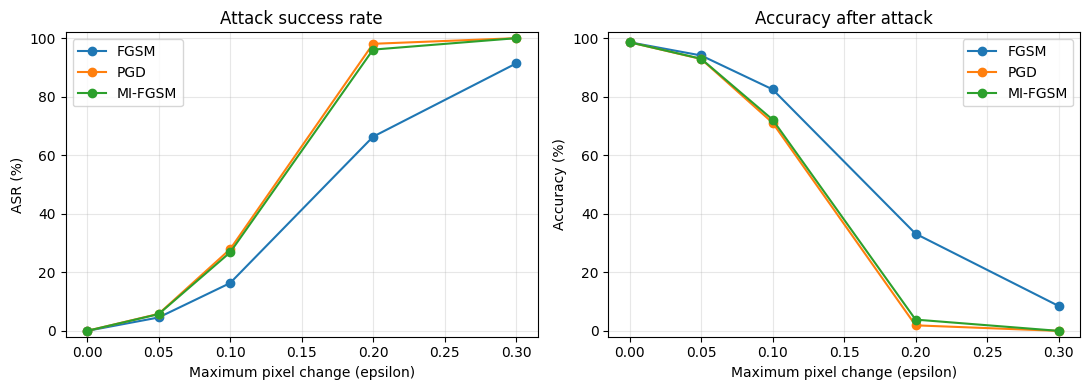

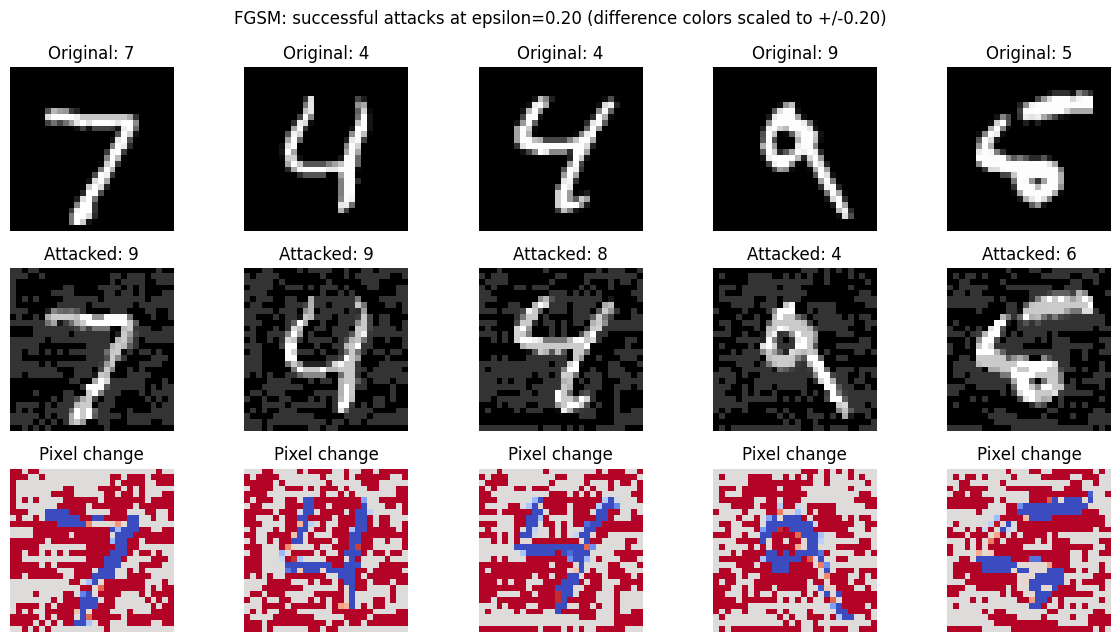

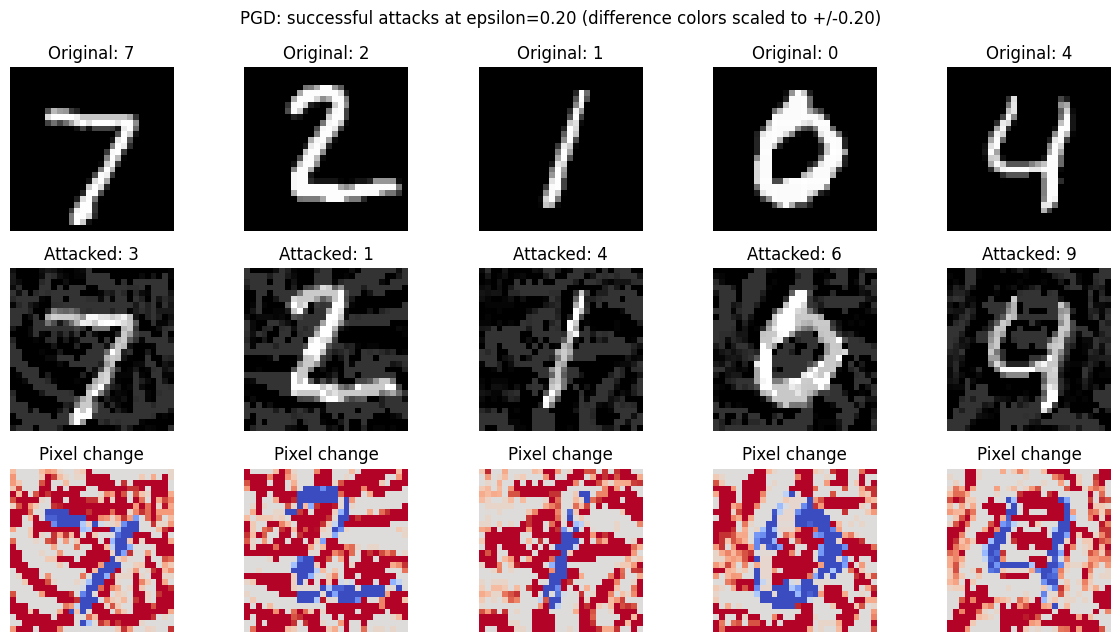

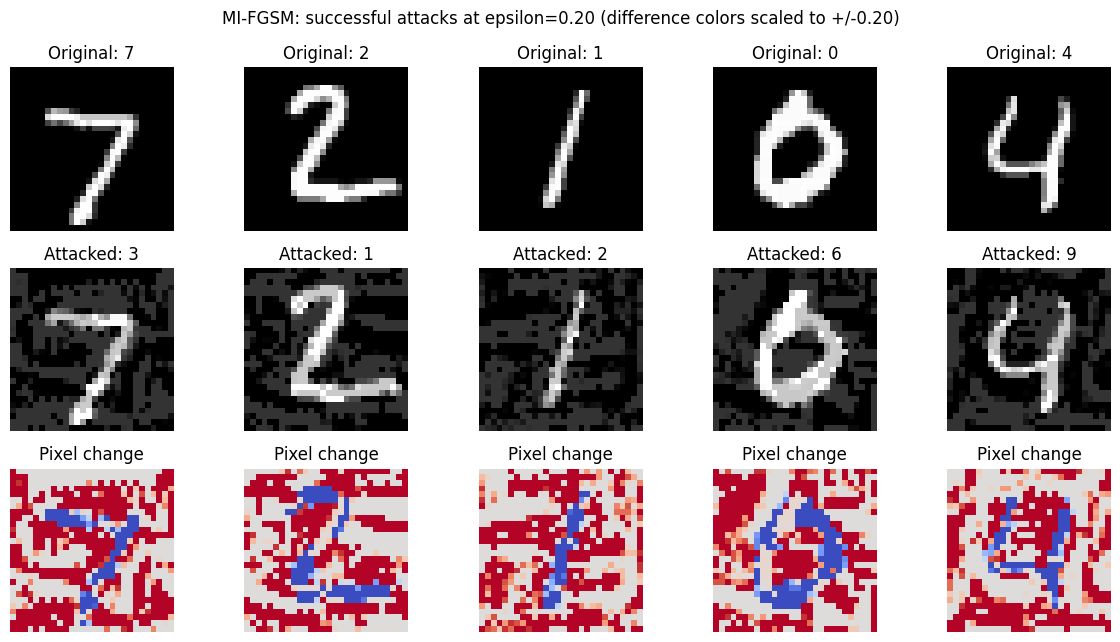


COMPLETED. Saved CSV, graphs, example images, settings, and RESULTS.md in mnist_results/
| attack   |   epsilon |   attacked_accuracy_pct |   asr_pct |
|:---------|----------:|------------------------:|----------:|
| FGSM     |      0.00 |                   98.61 |      0.00 |
| FGSM     |      0.05 |                   94.10 |      4.57 |
| FGSM     |      0.10 |                   82.51 |     16.33 |
| FGSM     |      0.20 |                   33.19 |     66.34 |
| FGSM     |      0.30 |                    8.52 |     91.36 |
| PGD      |      0.00 |                   98.61 |      0.00 |
| PGD      |      0.05 |                   92.89 |      5.80 |
| PGD      |      0.10 |                   71.10 |     27.90 |
| PGD      |      0.20 |                    1.89 |     98.08 |
| PGD      |      0.30 |                    0.00 |    100.00 |
| MI-FGSM  |      0.00 |                   98.61 |      0.00 |
| MI-FGSM  |      0.05 |                   92.97 |      5.72 |
| MI-FGSM  |      0.10 |    

,attack,epsilon,clean_accuracy_pct,attacked_accuracy_pct,asr_pct,successful_attacks,originally_correct,test_images,iterations,step_size,max_pixel_change,seconds
0,FGSM,0.00,98.61,98.61,0.000000,0,9861,10000,1,0.000,0.00,1.031871
1,FGSM,0.05,98.61,94.10,4.573573,451,9861,10000,1,0.050,0.05,1.142991
2,FGSM,0.10,98.61,82.51,16.326945,1610,9861,10000,1,0.100,0.10,1.161812
3,FGSM,0.20,98.61,33.19,66.342156,6542,9861,10000,1,0.200,0.20,1.122810
4,FGSM,0.30,98.61,8.52,91.359903,9009,9861,10000,1,0.300,0.30,1.077366
5,PGD,0.00,98.61,98.61,0.000000,0,9861,10000,20,0.000,0.00,1.015382
6,PGD,0.05,98.61,92.89,5.800629,572,9861,10000,20,0.005,0.05,4.544256
7,PGD,0.10,98.61,71.10,27.897779,2751,9861,10000,20,0.010,0.10,4.428583
8,PGD,0.20,98.61,1.89,98.083359,9672,9861,10000,20,0.020,0.20,4.436445
9,PGD,0.30,98.61,0.00,100.000000,9861,9861,10000,20,0.030,0.30,4.494316


In [ ]:
# Untargeted white-box L-infinity attacks on the same fixed MNIST model.
import pandas as pd
import torch.nn.functional as F
from IPython.display import display

assert "model" in globals(), "Run the training cell first."
model.eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)
EPSILONS = [0.0, 0.05, 0.10, 0.20, 0.30]
STEPS, MOMENTUM = 20, 1.0
out = Path("mnist_results")
out.mkdir(exist_ok=True)

def project_image(candidate, original, eps):
    return torch.maximum(torch.minimum(candidate, original + eps), original - eps).clamp(0, 1).detach()

def attack_images(original, labels, eps, method):
    x = original.detach()
    if eps == 0:
        return x.clone()
    if method == "FGSM":
        adv = x.clone().requires_grad_(True)
        gradient = torch.autograd.grad(F.cross_entropy(model(adv), labels), adv)[0]
        return project_image(adv + eps * gradient.sign(), x, eps)
    alpha = eps / 10
    # PGD uses a random start; momentum starts from the original image.
    adv = project_image(x + torch.empty_like(x).uniform_(-eps, eps), x, eps) if method == "PGD" else x.clone()
    velocity = torch.zeros_like(x)
    for _ in range(STEPS):
        adv = adv.detach().requires_grad_(True)
        gradient = torch.autograd.grad(F.cross_entropy(model(adv), labels), adv)[0]
        if method == "MI-FGSM":
            scale = gradient.abs().mean(dim=(1,2,3), keepdim=True).clamp_min(1e-12)
            velocity = MOMENTUM * velocity + gradient / scale
            direction = velocity.sign()
        else:
            direction = gradient.sign()
        adv = project_image(adv + alpha * direction, x, eps)
    return adv

# Baseline is recomputed on the full test split, never used to fit weights.
clean_predictions, true_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        clean_predictions.append(model(images.to(DEVICE)).argmax(1).cpu())
        true_labels.append(labels)
clean_predictions = torch.cat(clean_predictions)
true_labels = torch.cat(true_labels)
clean_mask = clean_predictions.eq(true_labels)
num_clean_correct = int(clean_mask.sum())
num_test = len(true_labels)
assert num_clean_correct > 0
print(f"BASELINE: {num_clean_correct}/{num_test} = {100*num_clean_correct/num_test:.2f}%", flush=True)

rows, example_bank = [], {}
for method in ["FGSM", "PGD", "MI-FGSM"]:
    for eps in EPSILONS:
        torch.manual_seed(SEED + int(round(eps*1000)))
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED + int(round(eps*1000)))
        attack_start = time.time()
        attacked_correct, successes, offset = 0, 0, 0
        max_delta, examples = 0.0, []
        for images, labels in test_loader:
            x, y = images.to(DEVICE), labels.to(DEVICE)
            adv = attack_images(x, y, eps, method)
            delta = float((adv-x).abs().max())
            max_delta = max(max_delta, delta)
            assert delta <= eps + 1e-6, "Perturbation exceeds budget"
            assert float(adv.min()) >= 0 and float(adv.max()) <= 1
            with torch.no_grad():
                prediction = model(adv).argmax(1).cpu()
            originally_correct = clean_mask[offset:offset+len(labels)]
            successful = originally_correct & prediction.ne(labels)
            attacked_correct += int(prediction.eq(labels).sum())
            successes += int(successful.sum())
            if eps == 0.20 and len(examples) < 5:
                for j in successful.nonzero(as_tuple=True)[0].tolist():
                    examples.append((images[j], adv[j].cpu(), int(labels[j]), int(prediction[j])))
                    if len(examples) == 5:
                        break
            offset += len(labels)
        assert offset == num_test
        if eps == 0:
            assert successes == 0 and attacked_correct == num_clean_correct
        row = {"attack": method, "epsilon": eps, "clean_accuracy_pct": 100*num_clean_correct/num_test, "attacked_accuracy_pct": 100*attacked_correct/num_test, "asr_pct": 100*successes/num_clean_correct, "successful_attacks": successes, "originally_correct": num_clean_correct, "test_images": num_test, "iterations": 1 if method == "FGSM" else STEPS, "step_size": eps if method == "FGSM" else eps/10, "max_pixel_change": max_delta, "seconds": time.time()-attack_start}
        rows.append(row)
        pd.DataFrame(rows).to_csv(out/"attack_results.csv", index=False)
        print(f"{method:8s} eps={eps:.2f}: accuracy={row['attacked_accuracy_pct']:.2f}%, ASR={row['asr_pct']:.2f}% ({successes}/{num_clean_correct}), {row['seconds']:.1f}s", flush=True)
        if eps == 0.20:
            example_bank[method] = examples

results = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for method, group in results.groupby("attack", sort=False):
    axes[0].plot(group.epsilon, group.asr_pct, marker="o", label=method)
    axes[1].plot(group.epsilon, group.attacked_accuracy_pct, marker="o", label=method)
for ax, title, ylabel in [(axes[0], "Attack success rate", "ASR (%)"), (axes[1], "Accuracy after attack", "Accuracy (%)")]:
    ax.set(xlabel="Maximum pixel change (epsilon)", ylabel=ylabel, title=title, ylim=(-2,102))
    ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(out/"attack_comparison.png", dpi=180)
plt.show()

for method, examples in example_bank.items():
    if not examples:
        continue
    fig, axes = plt.subplots(3, len(examples), figsize=(2.4*len(examples),6.5), squeeze=False)
    for col, (original, adversarial, truth, predicted) in enumerate(examples):
        axes[0,col].imshow(original.squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[0,col].set_title(f"Original: {truth}")
        axes[1,col].imshow(adversarial.squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[1,col].set_title(f"Attacked: {predicted}")
        axes[2,col].imshow((adversarial-original).squeeze(), cmap="coolwarm", vmin=-0.2, vmax=0.2)
        axes[2,col].set_title("Pixel change")
        for r in range(3):
            axes[r,col].axis("off")
    fig.suptitle(f"{method}: successful attacks at epsilon=0.20 (difference colors scaled to +/-0.20)")
    fig.tight_layout(); fig.savefig(out/f"examples_{method}.png", dpi=160)
    plt.show()

summary = results[["attack","epsilon","attacked_accuracy_pct","asr_pct"]].to_markdown(index=False, floatfmt=".2f")
report = f"# MNIST adversarial attack results\n\nClean accuracy: {100*num_clean_correct/num_test:.2f}% ({num_clean_correct}/{num_test}).\n\n{summary}\n\nASR = successful attacks among originally correct images / {num_clean_correct}. All attacks use the full {num_test}-image test set. FGSM uses one step; PGD and MI-FGSM use 20 steps with step size epsilon/10. PGD uses one seeded random start. MI-FGSM uses momentum 1.0 and mean-absolute-gradient normalization. Pixels are clipped to [0,1] and projected within epsilon of the original. Epsilon-zero and perturbation bounds were checked with assertions. These are empirical results for these settings, not certified robustness.\n"
(out/"RESULTS.md").write_text(report)
(out/"attack_settings.json").write_text(json.dumps({"epsilons":EPSILONS,"steps":STEPS,"momentum":MOMENTUM,"seed":SEED,"pgd_restarts":1,"threat_model":"untargeted white-box L-infinity","input_range":[0,1]}, indent=2))
print("\nCOMPLETED. Saved CSV, graphs, example images, settings, and RESULTS.md in mnist_results/", flush=True)
print(summary, flush=True)
display(results)


In [ ]:
# Package the actual executed source and measured results for GitHub.
import shutil, py_compile
repo = Path("ai-hw-fall-2026-aa")
repo.mkdir(exist_ok=True)
inputs = get_ipython().history_manager.input_hist_raw
train_source = next(s for s in reversed(inputs) if s.startswith("# MNIST baseline:"))
attack_source = next(s for s in reversed(inputs) if s.startswith("# Untargeted white-box"))
class_start = train_source.index("class MNISTCNN")
class_end = train_source.index("model = MNISTCNN", class_start)
model_source = train_source[class_start:class_end]
(repo/"model.py").write_text("from torch import nn\n\n" + model_source)
(repo/"train.py").write_text(train_source[:class_start] + "from model import MNISTCNN\n\n" + train_source[class_end:])
test_prefix = '''import json, random, time
from pathlib import Path
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from model import MNISTCNN
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MNISTCNN().to(DEVICE)
checkpoint = torch.load("mnist_results/mnist_cnn.pt", map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
test_data = datasets.MNIST("data", train=False, download=True, transform=transforms.ToTensor())
test_loader = DataLoader(test_data, batch_size=256, shuffle=False, num_workers=2)
'''
(repo/"test.py").write_text(test_prefix + "\n" + attack_source)
(repo/"requirements.txt").write_text("torch\ntorchvision\nnumpy\nmatplotlib\npandas\ntabulate\nipython\n")
(repo/".gitignore").write_text("data/\n__pycache__/\n.ipynb_checkpoints/\n*.zip\n")
readme = """# Attack MNIST Recognition

This project trains a small CNN on MNIST and compares untargeted FGSM, PGD, and Momentum I-FGSM attacks. The model uses two convolution/ReLU/pooling blocks and a 128-unit hidden layer. Training uses 60,000 images; evaluation uses the separate 10,000-image test set.

## Run
Use Python with the packages in requirements.txt. GPU is recommended, but the scripts also support CPU.

    pip install -r requirements.txt
    python train.py
    python test.py

train.py trains for five epochs using Adam (learning rate 0.001, batch size 128, seed 42), saves the checkpoint, and measures clean accuracy. test.py loads that checkpoint without retraining and evaluates the attacks. Run commands from the repository root. MNIST downloads automatically into data/. Results are written to mnist_results/.

## Attack settings
Inputs are in [0,1]. Epsilon values are 0, 0.05, 0.10, 0.20, 0.30. FGSM takes one step. PGD and MI-FGSM take 20 steps with step size epsilon/10. PGD uses one seeded random start; MI-FGSM uses momentum 1.0 and per-image mean-absolute-gradient normalization. All outputs are projected into the L-infinity epsilon ball and clipped to [0,1]. No adversarial training is performed.

## Metrics
Clean accuracy and attacked accuracy use all 10,000 test images. ASR counts only originally correct images that become incorrect after attack, divided by the number originally correct. Existing model mistakes do not count as successful attacks. The code asserts pixel bounds, perturbation limits, and zero-epsilon agreement with the baseline.

## Measured results
""" + report + """
## Interpretation and limitations
Compare attacks at the same epsilon. High clean accuracy does not guarantee resistance to adversarial examples. Iterative attacks can find stronger perturbations than a single gradient step in this experiment. Larger epsilon can visibly distort digits. These results concern one trained model, one seed and these settings. A single PGD start does not establish certified robustness. Five displayed examples per attack are successful cases at epsilon=0.20 and are not a random sample of the entire test set.

## Files
model.py defines the CNN; train.py trains it; test.py runs attacks and produces plots. mnist_results/ contains the checkpoint, CSV, baseline metrics, settings, comparison graph, example grids, and RESULTS.md. The submitted notebook contains training and attack code as well.

## References
- https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html
- https://docs.pytorch.org/tutorials/beginner/fgsm_tutorial.html
- FGSM: https://arxiv.org/abs/1412.6572
- PGD: https://arxiv.org/abs/1706.06083
- Momentum: https://arxiv.org/abs/1710.06081
"""
(repo/"README.md").write_text(readme)
shutil.copytree(out, repo/"mnist_results", dirs_exist_ok=True)
for script in ["model.py", "train.py", "test.py"]:
    py_compile.compile(str(repo/script), doraise=True)
# Record environment versions used for the measured run.
import torchvision
(repo/"environment.json").write_text(json.dumps({"torch":torch.__version__,"torchvision":torchvision.__version__,"numpy":np.__version__,"pandas":pd.__version__,"device":str(DEVICE)}, indent=2))
archive = shutil.make_archive("ai-hw-fall-2026-aa", "zip", root_dir=".", base_dir=str(repo))
print("READY:", archive, flush=True)
print("Result rows:", len(results), "; all 3 Python scripts compile successfully.", flush=True)
print(results[["attack","epsilon","attacked_accuracy_pct","asr_pct"]].to_string(index=False), flush=True)


READY: /content/ai-hw-fall-2026-aa.zip
Result rows: 15 ; all 3 Python scripts compile successfully.
 attack  epsilon  attacked_accuracy_pct    asr_pct
   FGSM     0.00                  98.61   0.000000
   FGSM     0.05                  94.10   4.573573
   FGSM     0.10                  82.51  16.326945
   FGSM     0.20                  33.19  66.342156
   FGSM     0.30                   8.52  91.359903
    PGD     0.00                  98.61   0.000000
    PGD     0.05                  92.89   5.800629
    PGD     0.10                  71.10  27.897779
    PGD     0.20                   1.89  98.083359
    PGD     0.30                   0.00 100.000000
MI-FGSM     0.00                  98.61   0.000000
MI-FGSM     0.05                  92.97   5.719501
MI-FGSM     0.10                  72.18  26.802556
MI-FGSM     0.20                   3.85  96.095731
MI-FGSM     0.30                   0.00 100.000000


## Final measured results

Clean test accuracy: **98.61% (9,861 / 10,000)**. The ASR denominator is 9,861 originally correct images. Each attack was evaluated on the same full test split.

| Attack | Epsilon | Accuracy after attack (%) | ASR (%) |
|---|---:|---:|---:|
| FGSM | 0.00 | 98.61 | 0.00 |
| FGSM | 0.05 | 94.10 | 4.57 |
| FGSM | 0.10 | 82.51 | 16.33 |
| FGSM | 0.20 | 33.19 | 66.34 |
| FGSM | 0.30 | 8.52 | 91.36 |
| PGD | 0.00 | 98.61 | 0.00 |
| PGD | 0.05 | 92.89 | 5.80 |
| PGD | 0.10 | 71.10 | 27.90 |
| PGD | 0.20 | 1.89 | 98.08 |
| PGD | 0.30 | 0.00 | 100.00 |
| Momentum I-FGSM | 0.00 | 98.61 | 0.00 |
| Momentum I-FGSM | 0.05 | 92.97 | 5.72 |
| Momentum I-FGSM | 0.10 | 72.18 | 26.80 |
| Momentum I-FGSM | 0.20 | 3.85 | 96.10 |
| Momentum I-FGSM | 0.30 | 0.00 | 100.00 |

### My takeaway
The CNN has high accuracy on original MNIST images, but it is vulnerable to adversarial changes. At epsilon=0.20, PGD has the highest ASR (98.08%), followed by Momentum I-FGSM (96.10%) and FGSM (66.34%). The iterative methods were stronger in this experiment. At epsilon=0.30, both iterative methods fooled every originally correct test image. Strong clean accuracy alone does not mean the model is robust. Larger changes can become visible, and results depend on the selected model and attack settings.

### Validation
All 15 configurations completed. Assertions checked image range, maximum pixel change, and zero-epsilon accuracy/ASR. The exported model.py, train.py, and test.py passed Python compilation. The scripts were extracted from the code executed here; the standalone scripts were not separately rerun.

### Submission files
The Files panel contains **ai-hw-fall-2026-aa.zip**. It includes training code, testing code, the saved checkpoint, CSV results, comparison graph, three grids of successful examples, settings, and README instructions. Download the ZIP, extract it, and upload the folder contents to a GitHub repository named **ai-hw-fall-2026-aa**. Also download this notebook using File > Download > Download .ipynb if you want to include it. Submit the GitHub repository URL to Canvas.

The ZIP download could not be verified from this browser session. Keep a copy before the temporary Colab runtime expires. If Colab cannot render outputs, the measured table above remains visible and saved in the notebook.
